In [1]:
import os
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
pth = os.path.join('..', '..', '..')
pth_in = os.path.join(pth, 'data', 'cancer', 'CCCA')
pth_out = os.path.join(pth, 'figures', 'cancer', 'CCCA')

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'malignant.h5ad'))
adata.X = np.asarray(adata.X.toarray() - adata.X.mean(axis = 1))
adata

AnnData object with n_obs × n_vars = 1406087 × 513
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'ebv', 'celltype', 'Title', 'Category', 'Disease', 'Technology', 'Samples', 'Cells', 'Name', 'patient', 'cell_subtype', 'source', 'disease', 'p16_status', 'site', 't_stage', 'n_stage', 'gender', 'race', 'age', 'tobacco_use', 'alcohol_use', 'hpv', 'hpv_score', 'treatment', 'procedure', 'sorting', 'cluster', 'malignant', 'sample_id', 'cell_subtype_clusters', 'tnm_stage', 'viral', 'location', 'cancer_type', 'treatment_exposure', 'treatment_response', 'cell_lineage', 'type', 'clusters_by_authors', 'cell_QCpass', 'is_tumor', 'cell_compartment', 'cluster_assignment', 'metastasis', 'sex', 'prior_enzalutamide', 'prior_abiraterone', 'prior_taxane', 'prior_platinum', 'prior_sipuleucel_T', 'purity', 'has_bulk_RNA', 'cancer_cell_state', 'PSA', 'source_region', 'gleason_score', 'ERG_status', 'cores

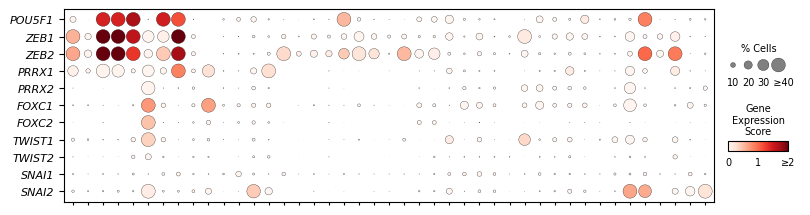

In [49]:
g_plt = ['POU5F1', 'ZEB1', 'ZEB2', 'PRRX1', 'PRRX2', 'FOXC1',
         'FOXC2', 'TWIST1', 'TWIST2', 'SNAI1', 'SNAI2']
ix = (adata.obs.groupby(['Category', 'Disease'], observed = True)
      .first().reset_index().Disease)

# expression dotplot
dp = sc.pl.dotplot(adata, g_plt, 'Disease',
                   categories_order = ix,
                   dot_max = .4,
                   vmin = 0, vmax = 2,
                   figsize = (9.5, 2.5),
                   swap_axes = True,
                   return_fig = True,
                   show = False)

dp.style(largest_dot = 100,
         x_padding = .6,
         y_padding = .6)
dp.legend(width = .8)

ax = dp.get_axes()
ax_main = ax['mainplot_ax']
ax_size = ax['size_legend_ax']
cax = ax['color_legend_ax']

ax_size.set_title('% Cells', size = 7, pad = -14)
ax_size.tick_params('x', size = 0, labelsize = 7, pad = .75)
ax_size.set_xticklabels(['10', '20', '30', '   ≥40'])
cax.set_title('Gene\nExpression\nScore', size = 7, pad = 5)
cax.set_xticks([0, 1, 2], ['0', '1', '≥2'])
cax.tick_params('x', size = 0, labelsize = 7, pad = 4.5)

pos_main = ax_main.get_position()
pos_size = ax_size.get_position()
pos_color = cax.get_position()

ax_size.set_position([.985 * pos_size.x0,
                      pos_main.y0 + .65 * pos_main.height,
                      pos_size.width,
                      pos_size.height])

cax.set_position([.985 * pos_color.x0,
                  pos_main.y0 + .265 * pos_main.height,
                  pos_color.width,
                  .7 * pos_color.height])

ax_main.set_xticklabels([])
ax_main.tick_params('x', size = 2.5)
ax_main.set_yticklabels(ax_main.get_yticklabels(),
                        fontsize = 8,
                        fontstyle = 'italic')

fn = os.path.join(pth_out, 'expression.pdf')
plt.savefig(fn, bbox_inches = 'tight')